<a href="https://colab.research.google.com/github/vivekpandey0706/Bigram_Tigram_name_generator/blob/main/Bigram_Trigram_Names_generator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Language Learning Models: ngram generator
This project builds two language models namely bigram and trigram from scrach using PyTorch. The dataset contains 32,033 names from which the models learn.It has been shuffled and divided into training (80%), validation(10%) and test sets(10%).

This notebook also evaluates the average loss (negative log likelihood per character) on the validation set and compares it with uniformly guessed words

It also smoothens the data so that our models can create new pairs (or triplets) of combinations of letters.

After learning, it also generates new names by predicting each character from the previous one (in case of bigram) or two (in case of trigram) characters.


---


**Result:** The trigram model got a loss of 2.22 on the test set,bigram model got loss of 2.46 while 3.30 is the loss for random guessing.

In [ ]:
import torch
import matplotlib.pyplot as plt
import random #for splitting into training, test and validation sets


In [ ]:

!wget -nc https://raw.githubusercontent.com/karpathy/makemore/master/names.txt #downloads the dataset

def load_data(path):
  with open(path, "r", encoding = "utf-8") as f: #encoding is required in case some other language or emoji text is there
    data = f.read().splitlines()
  return data

path = "names.txt"
data = load_data(path)

def split_data(data, seed, ratio_train, ratio_test, ratio_validate):
  random.seed(seed)
  temp_data = list(data)
  random.shuffle(temp_data)
  data_size = len(data)
  training_size = int(ratio_train * data_size)
  testing_size = int(ratio_test * data_size)
  validating_size = int(ratio_validate * data_size)
  training_data, validation_set , testing_set= temp_data[:training_size], temp_data[training_size:training_size+validating_size ], temp_data[training_size+validating_size:]

  return training_data,  validation_set, testing_set

training_data, validation_set ,testing_set = split_data(data, 42, 0.8, 0.1 , 0.1)



--2026-10-17 16:39:15--  https://raw.githubusercontent.com/karpathy/makemore/master/names.txt
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 228145 (223K) [text/plain]
Saving to: ‘names.txt’

names.txt           100%[===================>] 222.80K  --.-KB/s    in 0.02s   

2026-10-17 16:39:15 (8.93 MB/s) - ‘names.txt’ saved [228145/228145]



In [ ]:
def build_vocab(data):
  stoi = {}
  itos = {}
  distinct_letters = set()
  stoi['.'] = 0
  itos[0] = '.'
  for word in data:
    for ch in word:
      if ch not in stoi:
        distinct_letters.add(ch)
  sorted_letters = list(sorted(distinct_letters))
  for idx, ch in enumerate(sorted_letters):
    stoi[ch] = idx + 1
    itos[idx+1] = ch
  return stoi, itos

stoi , itos = build_vocab(data)



In [ ]:
def count_bigrams(training_data, stoi):
  bigram_freq = torch.zeros((27,27))
  for word in training_data:
    n = len(word)
    bigram_freq[0,stoi[word[0]]] +=1
    bigram_freq[stoi[word[n-1]],0] +=1
    pairs = list(zip(word, word[1:]))
    for pair in pairs:
      bigram_freq[stoi[pair[0]],stoi[pair[1]]] +=1
  return bigram_freq

bigram_freq = count_bigrams(training_data, stoi)



In [ ]:
def count_trigrams(training_data , stoi):
  tri_freq = torch.zeros((27,27,27))
  for word in training_data:
    n = len(word)
    tri_freq[0,0, stoi[word[0]]] +=1
    tri_freq[0, stoi[word[0]] , stoi[word[1]]]+=1
    tri_freq[stoi[word[n-2]] , stoi[word[n-1]], 0] +=1
    triplets = list(zip(word, word[1:], word[2:]))
    for triplet in triplets:
      tri_freq[stoi[triplet[0]], stoi[triplet[1]], stoi[triplet[2]]] +=1
  return tri_freq

trigram_freq = count_trigrams(training_data, stoi)


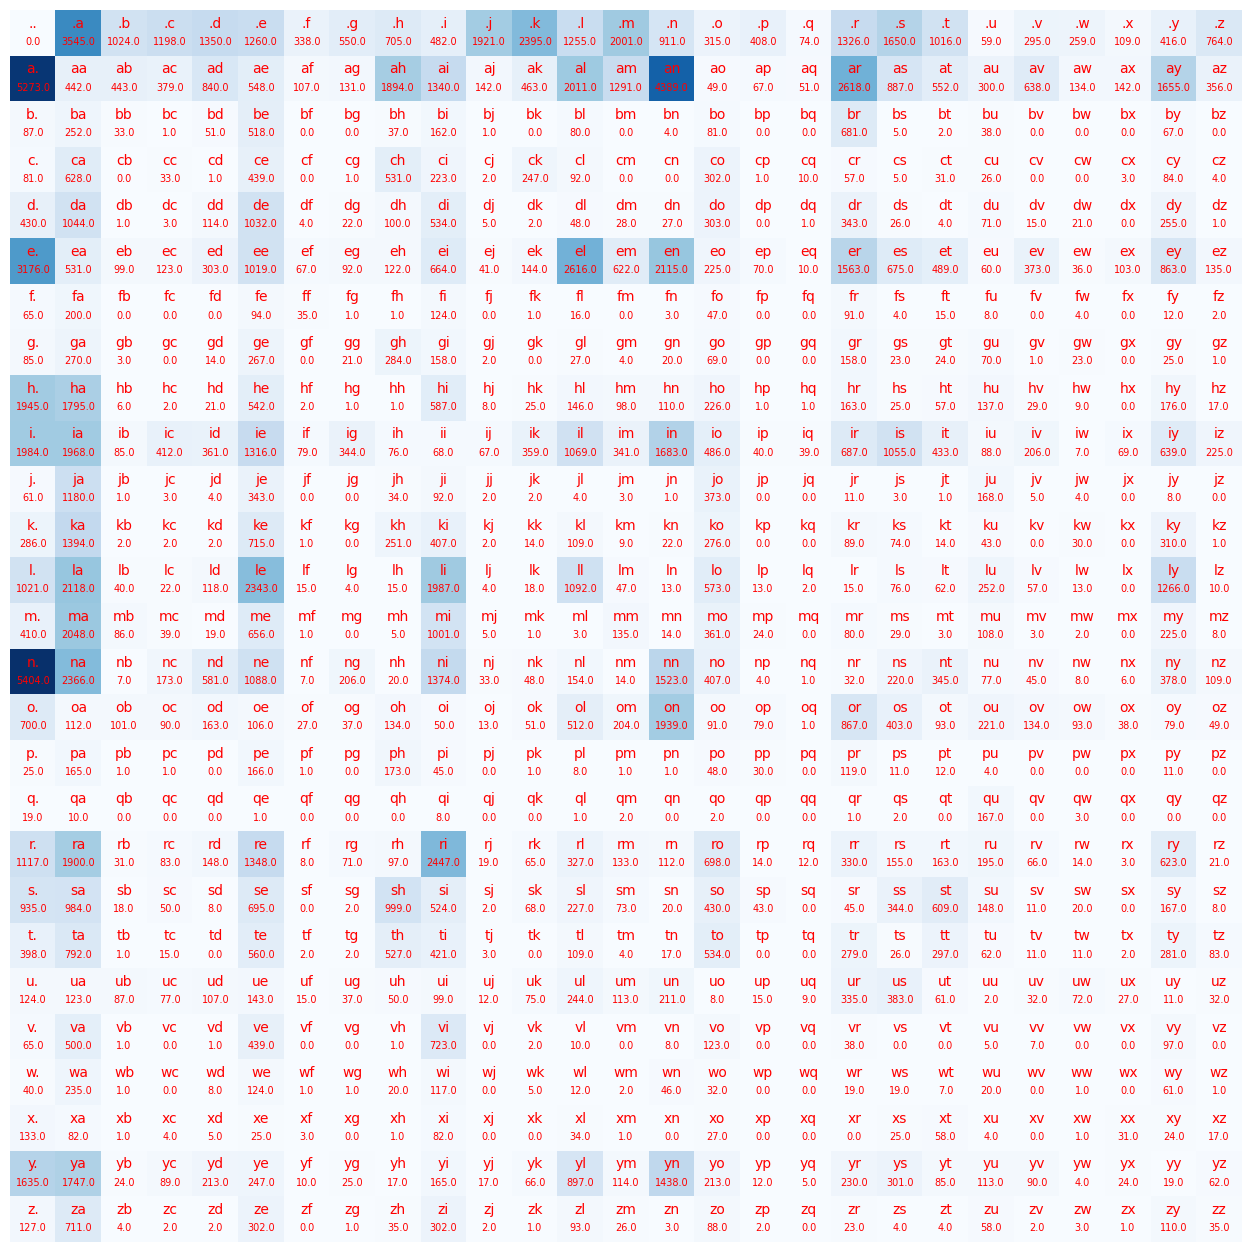

In [ ]:
#Visualizing frequency heatmap for every pair in training set. (for bigram model)

plt.figure(figsize=(16,16))
plt.imshow(bigram_freq, cmap='Blues')
for i in range(bigram_freq.shape[0]):
  for j in range(bigram_freq.shape[1]):
    plt.text(j, i-0.2, str(itos[i] + itos[j]), ha = "center" , va = "center", color = "red")
    plt.text(j, i+0.2, str(bigram_freq[i,j].item()), ha = "center" , va = "center", color = "red", fontsize = 7)
plt.axis("off")
plt.show()

In [ ]:
def make_probs(freq,k):
  smooth_counts = freq + k #adding k-smoothening, so that the pairs that aren't in my training set, also have some chance of showing up

  smooth_prob = smooth_counts / smooth_counts.sum(dim =-1, keepdim = True)
  return smooth_prob



In [ ]:
def sample_bigram_name(bigram_prob, itos, generator):
  current_index = 0
  name = ""
  while True:
    probs = bigram_prob[current_index]
    index = torch.multinomial(probs, num_samples=1, generator = generator)
    if index.item() == 0:
      return name
    name += itos[index.item()]
    current_index = index.item()


def sample_trigram_name(trigram_prob, itos, generator):
  current_pos = [0,0]
  name = ""
  while True:
    probs = trigram_prob[current_pos[0] , current_pos[1]]
    index1= torch.multinomial(probs, num_samples =1 , generator = generator)
    if index1.item() == 0:
      return name
    name += itos[index1.item()]
    current_pos = [current_pos[1], index1.item()]



In [ ]:

#Samples for each model

bigram_prob = make_probs(bigram_freq,0)      #model1
trigram_prob = make_probs(trigram_freq, 0)   #model2
rand_prob = torch.ones((27,27))/27           #model3


generator1 = torch.Generator().manual_seed(42) #change seed to get some other values from same prob distribution
generator2 = torch.Generator().manual_seed(42)
generator3 = torch.Generator().manual_seed(42)

for i in range(15):
  name_bigram = sample_bigram_name(bigram_prob,itos,generator1)
  name_trigram = sample_trigram_name(trigram_prob, itos, generator3)
  rand_name = sample_bigram_name(rand_prob, itos, generator2)
  print(f"bigram name: {name_bigram:<25} trigram name: {name_trigram:<25} random choice : {rand_name}")

bigram name: anugeenvi                 trigram name: anuee                     random choice : xjugueovtps
bigram name: s                         trigram name: nat                       random choice : fabiquedxfmubnwmsflaypggzofmwhwlxoln
bigram name: mabidushan                trigram name: syna                      random choice : epjccuodsgjdmzu
bigram name: stan                      trigram name: idushante                 random choice : xnxcmjjobdrggbdllk
bigram name: silaylelaremah            trigram name: na                        random choice : mnqhqyjfbhcvghigeaczalcvjwiajwtphjpdmqsotcc
bigram name: li                        trigram name: silayley                  random choice : welqxosvgkocobr
bigram name: le                        trigram name: kemah                     random choice : uklnncvrigmydysoumf
bigram name: epiachalen                trigram name: lucin                     random choice : pjjiewx
bigram name: diza                      trigram name: epiah          

In [ ]:
def avg_loss_bigram(validation_set, bigram_prob, stoi):
  total_loss = 0
  total_pairs = 0
  for word in validation_set:
    len_word = len(word)
    total_pairs += len_word +1
    total_loss += torch.log(bigram_prob[0,stoi[word[0]]])
    total_loss += torch.log(bigram_prob[stoi[word[-1]],0])
    pairs = list(zip(word, word[1:]))
    for pair in pairs:
      total_loss += torch.log(bigram_prob[stoi[pair[0]], stoi[pair[1]]])
      #taking log in prob as it is a smol number, so to avoid underflow

  total_loss *= (-1)
  loss = total_loss/total_pairs
  return loss
#lesser loss is better (better at prediction)
#perplexity - e^loss -> effective number of equally likely choices

def avg_loss_trigram(validation_set, trigram_prob, stoi):
  total_loss = 0
  total_triplets = 0
  for word in validation_set:
    len_word = len(word)
    total_triplets += len_word +1
    total_loss += torch.log(trigram_prob[0,0,stoi[word[0]]])
    total_loss += torch.log(trigram_prob[0,stoi[word[0]] , stoi[word[1]]])
    total_loss += torch.log(trigram_prob[stoi[word[-2]], stoi[word[-1]] , 0])
    triplets = list(zip(word, word[1:], word[2:]))
    for triplet in triplets:
      total_loss += torch.log(trigram_prob[stoi[triplet[0]], stoi[triplet[1]], stoi[triplet[2]]])

  total_loss *= (-1)
  loss = total_loss/total_triplets
  return loss



In [ ]:
#Finding the values of loss functions for various values of k, for bigram , trigram and
values = [0, 0.01,0.1,0.5,1,10,100,1000,100000,10000000]
for k in values:
  bigram_prob = make_probs(bigram_freq, k)
  trigram_prob = make_probs(trigram_freq, k)
  rand_prob = torch.ones((27,27))/27
  loss_bigram = avg_loss_bigram(validation_set, bigram_prob, stoi)
  loss_trigram = avg_loss_trigram(validation_set, trigram_prob, stoi)
  loss_rand = avg_loss_bigram(validation_set , rand_prob, stoi)
  print(f"Bigram: k = {k:>8}: loss = {loss_bigram:<10.4f}  Trigram: k ={k:>8}: loss = {loss_trigram:<10.4f} Random: {loss_rand}")


Bigram: k =        0: loss = inf         Trigram: k =       0: loss = nan        Random: 3.296229362487793
Bigram: k =     0.01: loss = 2.4535      Trigram: k =    0.01: loss = 2.2318     Random: 3.296229362487793
Bigram: k =      0.1: loss = 2.4530      Trigram: k =     0.1: loss = 2.2225     Random: 3.296229362487793
Bigram: k =      0.5: loss = 2.4530      Trigram: k =     0.5: loss = 2.2267     Random: 3.296229362487793
Bigram: k =        1: loss = 2.4533      Trigram: k =       1: loss = 2.2365     Random: 3.296229362487793
Bigram: k =       10: loss = 2.4627      Trigram: k =      10: loss = 2.3637     Random: 3.296229362487793
Bigram: k =      100: loss = 2.5544      Trigram: k =     100: loss = 2.7464     Random: 3.296229362487793
Bigram: k =     1000: loss = 2.8941      Trigram: k =    1000: loss = 3.1366     Random: 3.296229362487793
Bigram: k =   100000: loss = 3.2861      Trigram: k =  100000: loss = 3.2935     Random: 3.296229362487793
Bigram: k = 10000000: loss = 3.2962  

In [ ]:
#Test set
prob_heatmap_trigram = make_probs(trigram_freq,0.1)
prob_heatmap_bigram = make_probs(bigram_freq,0.1)
loss_test_set_trigram = avg_loss_trigram(testing_set, prob_heatmap_trigram, stoi)
loss_test_set_bigram = avg_loss_bigram(testing_set, prob_heatmap_bigram, stoi)
print(f"Final minimum loss on test set via trigram at k = 0.1: {loss_test_set_trigram:.4f}")
print(f"Final minimum loss on test set via trigram at k = 0.1: {loss_test_set_bigram:.4f}")


Final minimum loss on test set via trigram at k = 0.1: 2.2240
Final minimum loss on test set via trigram at k = 0.1: 2.4579
